# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

**Aluno**: Adair José Limana

---

# Desafio Final — Diagnóstico de Gases por Sensores Químicos

## Pipeline Completo de Classificação: do dado bruto ao modelo salvo

Este é o desafio de encerramento do módulo de **Modelos de Classificação**.


Um arranjo de 16 sensores químicos de óxido metálico, instalado em um ambiente controlado (Industrial SENAI AI), foi exposto a 6 gases puros diferentes, em diversas concentrações, ao longo de 36 meses de coleta. A cada exposição, os sensores registram uma resposta elétrica que é processada em um conjunto de características numéricas.

O problema: a partir dessas características, identificar qual dos 6 gases está sendo detectado. Este é um problema clássico de diagnóstico automático por sensores — o mesmo princípio usado em narizes eletrônicos industriais para controle de qualidade do ar, detecção de vazamentos e monitoramento ambiental.

## Objetivos do desafio

Ao final, você deve ser capaz de demonstrar que sabe:

1. (EDA) Carregar e preparar um dataset real de sensores, identificando quais colunas realmente são features do problema.
2. (Pre-processamento) Comparar o efeito de diferentes `Scaler`s no treinamento.
3. (Treinamento )Comparar todos os classificadores vistos em aula sob o mesmo protocolo de validação cruzada normal e validação estratificada.
4. (Treinamento) Escolher métricas adequadas para um problema **multiclasse balanceado** .
5. (Treinamento) Ajustar hiperparâmetros dos modelos finalistas.
6. (CRISP-DM - Pre-processamento)Comparar o uso de **todas as colunas** contra **PCA** e contra um **método de seleção de atributos** e, desta vez, avaliar se o ganho é real.
7. Avaliar o modelo final no conjunto de teste com múltiplas métricas.
8. Salvar o pipeline completo e reutilizá-lo para prever um caso novo.

## O dataset: Gas Sensor Array Drift Dataset at Different Concentrations (UCI id 270)

Este dataset foi coletado no **ChemoSignals Laboratory** (BioCircuits Institute, UC San Diego), ao longo de **36 meses**, com um arranjo de **16 sensores químicos de óxido metálico** expostos a **6 gases puros diferentes**, em várias concentrações. O objetivo é identificar **qual gás** está sendo detectado a partir da resposta dos sensores.

### Estrutura das features

Cada um dos 16 sensores gera **8 características** por medição (2 características de regime estacionário + 6 características dinâmicas, extraídas da resposta do sensor ao longo do tempo). Isso resulta em **16 × 8 = 128 colunas numéricas**, todas contínuas.

### A variável-alvo

| Classe | Gás | Faixa de concentração testada (ppmv) |
|---|---|---|
| 1 | Amônia | 50 – 1000 |
| 2 | Acetaldeído | 5 – 500 |
| 3 | Acetona | 12 – 1000 |
| 4 | Etileno | 10 – 300 |
| 5 | Etanol | 10 – 600 |
| 6 | Tolueno | 10 – 100 |


As features (V1 a V128)

Cada um dos 16 sensores gera 8 características por medição:

2 características de regime estacionário (amplitude da variação de resistência, em valor absoluto e normalizado);
6 características dinâmicas (extraídas da forma como o sinal sobe e desce ao longo do tempo, via médias móveis exponenciais em diferentes velocidades).

#Imports e dataset

In [157]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import time

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV, RandomizedSearchCV,
)
from scipy.stats import loguniform, randint
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

print('Bibliotecas carregadas com sucesso.')

Bibliotecas carregadas com sucesso.


In [190]:
BASE_URL = 'https://raw.githubusercontent.com/AdaLimana/pos-ia/refs/heads/main/ma/project-01/'

df_original = pd.read_csv(BASE_URL + 'gassensor_array.csv')

df = df_original.copy()

print('Dados carregados com sucesso!')
print(f'Registros: {df.shape[0]} registros\n')

print(f'Colunas do DF carregado: {df.columns}\n')
print(f'Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

Dados carregados com sucesso!
Registros: 13910 registros

Colunas do DF carregado: Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       ...
       'V120', 'V121', 'V122', 'V123', 'V124', 'V125', 'V126', 'V127', 'V128',
       'Class'],
      dtype='object', length=129)

Possui: 13910 linhas, 129 colunas.


##Conhecendo os dados

In [159]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V120,V121,V122,V123,V124,V125,V126,V127,V128,Class
0,12285.6582,4.076635,4.842317,7.509393,10.822436,-1.312657,-1.853717,-6.924985,11800.9233,4.483500,...,-3.440387,1784.5324,1.907000,1.729200,4.881194,8.623828,-0.314110,-0.661556,-3.521663,4
1,-35.6889,0.993944,0.166099,0.489363,3.484663,-0.130298,-0.528364,-3.735347,266.4145,1.053988,...,-4.482534,904.9898,1.433707,1.068069,2.532958,5.369720,-0.183779,-0.534087,-4.635975,3
2,63927.2217,14.956941,19.971376,29.188512,33.291320,-10.433776,-16.062245,-49.490143,57405.8483,15.613843,...,-25.150090,14585.7879,8.189021,6.099452,12.127991,15.709651,-3.887082,-6.731473,-19.326895,4
3,2992.9019,1.380553,0.808910,1.288259,4.660135,-0.755903,-1.120470,-4.075213,4301.4033,1.652701,...,-7.215792,6044.5554,3.488295,2.662288,5.938297,8.544508,-1.567322,-2.701235,-6.472439,3
4,57524.7812,11.912566,14.631496,19.809240,23.715868,-9.084750,-11.770585,-39.234003,50051.0703,11.732548,...,-10.248794,10580.1006,5.752675,3.880740,8.545897,11.831716,-2.655521,-4.312744,-8.510591,4


# Funções Utilitárias e Constantes

In [189]:
TARGET_COLUMN = 'Class'
SEED = 77

CLASSIFICATORS_LABEL = {
    "LOGISTIC": "Regressão Logística",
    "KNN": "K-NN",
    "MLP": "Rede Neural (MLP)",
    "RANDOM_FOREST": "Random Forest",
    "GRADIENT_BOSTING": "Gradient Boosting",
    "SVM": "SVM",
    "LDA": "LDA",
    "DECISION_TREE": "Árvore de Decisão",
    "NAIVE_BAYES": "Naive Bayes",
}

def format_probabilities(probabilities, classes):
    """Converte um array de probabilidades em um dicionário limpo {classe: probabilidade}, pronto para imprimir."""
    return {class_: round(float(p), 3) for class_, p in zip(classes, probabilities)}

#Qualidade dos dados

In [161]:
print(f"REGISTROS DUPLICADOS")
qtd_linhas_antes = df.shape[0]
df = df.drop_duplicates()
qtd_linhas_removidas = qtd_linhas_antes - df.shape[0]

if qtd_linhas_removidas > 0:
  print(f'Foram removidas {qtd_linhas_antes} registro(s) duplicado(s)\n')
else:
  print(f'Não possui valore duplicados\n')

print(f"VALORES AUSENTES")
nulos = df.isnull().sum()
colunas_com_nulos = nulos[nulos > 0]
total = df.shape[0]

if len(colunas_com_nulos):
  for col, qtd in colunas_com_nulos.items():
    print(f"'{col}': {qtd} nulos ({qtd/total:.1%})")
else:
  print("Sem valores ausentes")

REGISTROS DUPLICADOS
Não possui valore duplicados

VALORES AUSENTES
Sem valores ausentes


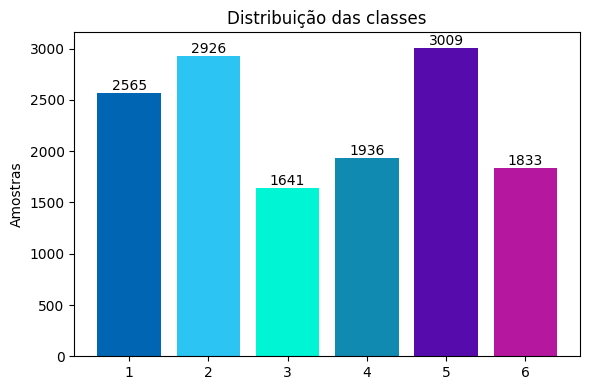

In [162]:
count = df[TARGET_COLUMN].value_counts().sort_index()
CLASS_NAME = [str(name) for name in set(df[TARGET_COLUMN])]

plt.figure(figsize=(6, 4))
plt.bar(CLASS_NAME, count.values, color=["#0066B3", "#2BC4F3", "#00F5D4", "#118AB2", "#560BAD", "#B5179E"])
for position, value in enumerate(count.values):
    plt.text(position, value, str(value), ha="center", va="bottom")
plt.title("Distribuição das classes")
plt.ylabel("Amostras")
plt.tight_layout()
plt.show()

In [163]:
df.drop(columns=TARGET_COLUMN).describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
V1,50435.1,69844.8,-16757.6,670687.3
V2,6.6,13.5,0.1,1339.9
V3,12.9,17.6,0.0,167.1
V4,18.7,24.9,0.0,226.6
V5,26.9,38.1,0.0,993.6
...,...,...,...,...
V124,14.9,12.4,0.0,297.2
V125,19.1,14.4,0.1,195.2
V126,-4.9,4.2,-30.2,-0.0
V127,-8.2,7.6,-58.8,6.9


#Divisão dos dados para treino e teste

In [165]:
X = df.drop(columns=TARGET_COLUMN)
y = df[TARGET_COLUMN]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

print(f"Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras")
print("Proporção de classes no treino:", y_treino.value_counts(normalize=True).sort_index().round(2).tolist())
print("Proporção de classes no teste: ", y_teste.value_counts(normalize=True).sort_index().round(2).tolist())

Treino: 9737 amostras | Teste: 4173 amostras
Proporção de classes no treino: [0.18, 0.21, 0.12, 0.14, 0.22, 0.13]
Proporção de classes no teste:  [0.18, 0.21, 0.12, 0.14, 0.22, 0.13]


#Comparando acurácia com diferentes Scalers

In [166]:
from sklearn.tree import DecisionTreeClassifier

scalers = {
    "Sem scaler": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

test_classificators = {
    "K-NN (distância)": KNeighborsClassifier(n_neighbors=5),
    "Árvore de Decisão (cortes)": DecisionTreeClassifier(random_state=SEED)
}

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scalers_result = []

for scaler_name, scaler in scalers.items():
  for model_name, model in test_classificators.items():
    stages = [("modelo", model)] if scaler is None else [("escalonador", scaler), ("modelo", model)]
    pipeline = Pipeline(stages)
    scores = cross_val_score(pipeline, X_treino, y_treino, cv=cross_validation, scoring="accuracy")
    scalers_result.append({"scaler": scaler_name, "modelo": model_name, "acuracia": scores.mean()})

scaler_table = pd.DataFrame(scalers_result).pivot(index="scaler", columns="modelo", values="acuracia")

scaler_table = scaler_table.reindex(["Sem scaler", "StandardScaler", "MinMaxScaler", "RobustScaler"])
scaler_table.round(3)

modelo,K-NN (distância),Árvore de Decisão (cortes)
scaler,,
Sem scaler,0.974,0.967
StandardScaler,0.987,0.967
MinMaxScaler,0.989,0.967
RobustScaler,0.986,0.967


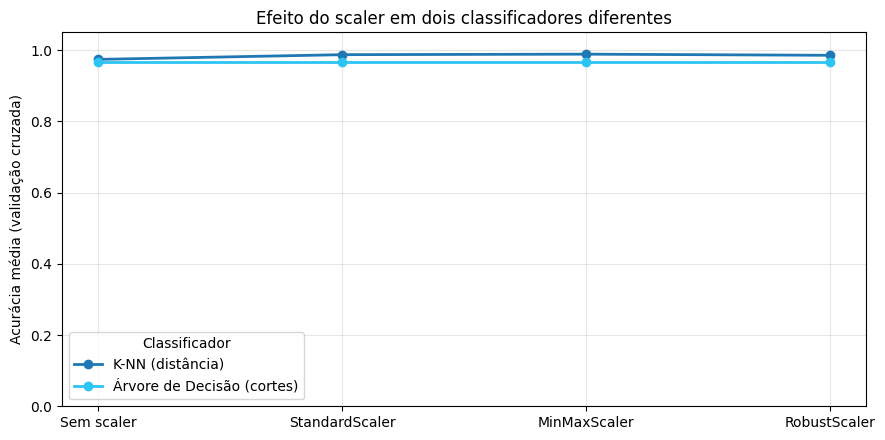

In [167]:
plt.figure(figsize=(9, 4.5))

colors={"k-NN (distância)": "#0066B3", "Árvore de Decisão (cortes)": "#2BC4F3"}
for model_name in scaler_table.columns:
  plt.plot(scaler_table.index, scaler_table[model_name], marker="o",
           linewidth=2, label=model_name, color=colors.get(model_name))
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("Efeito do scaler em dois classificadores diferentes")
plt.ylim(0, 1.05)
plt.legend(title="Classificador")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Instanciando os modelos e configurando as pipelines

In [168]:
logistic_model = LogisticRegression(max_iter=1000, random_state=SEED)
knn_model = KNeighborsClassifier(n_neighbors=5)
svm_model = SVC(kernel="rbf", probability=True, random_state=SEED)
tree_model = DecisionTreeClassifier(max_depth=5, random_state=SEED)
random_forest_model = RandomForestClassifier(n_estimators=200, random_state=SEED)
gradient_boosting_model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=SEED)
naive_bayes_model = GaussianNB()
lda_model = LinearDiscriminantAnalysis()
mlp_model = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=SEED)

In [169]:
classificators_result = { "common_validation": [], "stratified_validation": [] }
classificators_table = { }
classificators = {
    CLASSIFICATORS_LABEL["LOGISTIC"]: logistic_model,
    CLASSIFICATORS_LABEL["KNN"]: knn_model,
    CLASSIFICATORS_LABEL["SVM"]: svm_model,
    CLASSIFICATORS_LABEL["DECISION_TREE"]: tree_model,
    CLASSIFICATORS_LABEL["RANDOM_FOREST"]: random_forest_model,
    CLASSIFICATORS_LABEL["GRADIENT_BOSTING"]: gradient_boosting_model,
    CLASSIFICATORS_LABEL["NAIVE_BAYES"]: naive_bayes_model,
    CLASSIFICATORS_LABEL["LDA"]: lda_model,
    CLASSIFICATORS_LABEL["MLP"]: mlp_model
}

pipelines = { }

for name, model in classificators.items():
  pipeline = Pipeline([("escalonador", StandardScaler()), ("modelo", model)])
  pipelines[name] = pipeline


#Comparando classificadores usando validação cruzada (K-Fold)

In [170]:
common_cross_validation = KFold(n_splits=5, shuffle=True, random_state=SEED)

In [171]:
classificators_result["common_validation"] = []

for name, model in classificators.items():
  start = time.time()
  pipeline = pipelines.get(name)
  scores = cross_val_score(pipeline, X_treino, y_treino, cv=common_cross_validation, scoring="accuracy", n_jobs=-1)
  end = time.time()
  classificators_result["common_validation"].append({"classificador": name, "acuracia_media": scores.mean(),
                                       "desvio": scores.std(), "tempo_gasto_treinamento (s)": (end - start)})

classificators_table["common_validation"] = (pd.DataFrame(classificators_result["common_validation"])
                          .set_index("classificador").sort_values("acuracia_media", ascending=False))

print(classificators_table["common_validation"].round(3))

                     acuracia_media  desvio  tempo_gasto_treinamento (s)
classificador                                                           
Rede Neural (MLP)             0.993   0.002                       42.390
Random Forest                 0.993   0.002                       85.374
Gradient Boosting             0.991   0.002                     2166.250
Regressão Logística           0.989   0.001                        9.959
K-NN                          0.988   0.002                        1.267
SVM                           0.972   0.008                       44.728
LDA                           0.944   0.005                        2.013
Árvore de Decisão             0.804   0.008                        3.945
Naive Bayes                   0.567   0.006                        0.493


In [172]:
classificators_result["common_validation"] = []

for name, model in classificators.items():
  start = time.time()
  pipeline = pipelines.get(name)
  scores = cross_val_score(pipeline, X_treino, y_treino, cv=common_cross_validation, scoring="accuracy", n_jobs=-1)
  end = time.time()
  classificators_result["common_validation"].append({"classificador": name, "acuracia_media": scores.mean(),
                                       "desvio": scores.std(), "tempo_gasto_treinamento (s)": (end - start)})

classificators_table["common_validation"] = (pd.DataFrame(classificators_result["common_validation"])
                          .set_index("classificador").sort_values("acuracia_media", ascending=False))

print(classificators_table["common_validation"].round(3))

                     acuracia_media  desvio  tempo_gasto_treinamento (s)
classificador                                                           
Rede Neural (MLP)             0.993   0.002                       43.097
Random Forest                 0.993   0.002                       85.758
Gradient Boosting             0.991   0.002                     2141.103
Regressão Logística           0.989   0.001                        6.441
K-NN                          0.988   0.002                        1.955
SVM                           0.972   0.008                       47.723
LDA                           0.944   0.005                        1.963
Árvore de Decisão             0.804   0.008                        3.873
Naive Bayes                   0.567   0.006                        0.531


#Comparando classificadores usando validação cruzada estratificada (Stratified K-Fold)

In [173]:
stratified_cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [174]:
classificators_result["stratified_validation"] = []

for name, model in classificators.items():
  start = time.time()
  pipeline = pipelines.get(name)
  scores = cross_val_score(pipeline, X_treino, y_treino, cv=stratified_cross_validation, scoring="accuracy", n_jobs=-1)
  end = time.time()
  classificators_result["stratified_validation"].append({"classificador": name, "acuracia_media": scores.mean(),
                                       "desvio": scores.std(), "tempo_gasto_treinamento (s)": (end - start)})

classificators_table["stratified_validation"] = (pd.DataFrame(classificators_result["stratified_validation"])
                          .set_index("classificador").sort_values("acuracia_media", ascending=False))

print(classificators_table["stratified_validation"].round(3))

                     acuracia_media  desvio  tempo_gasto_treinamento (s)
classificador                                                           
Rede Neural (MLP)             0.993   0.002                       48.854
Random Forest                 0.992   0.001                       85.092
Gradient Boosting             0.992   0.001                     2153.563
Regressão Logística           0.988   0.003                        7.528
K-NN                          0.987   0.002                        1.233
SVM                           0.971   0.004                       48.897
LDA                           0.944   0.005                        3.207
Árvore de Decisão             0.804   0.005                        4.609
Naive Bayes                   0.568   0.010                        0.944


In [175]:
classificators_result["stratified_validation"] = []

for name, model in classificators.items():
  start = time.time()
  pipeline = pipelines.get(name)
  scores = cross_val_score(pipeline, X_treino, y_treino, cv=stratified_cross_validation, scoring="accuracy", n_jobs=-1)
  end = time.time()
  classificators_result["stratified_validation"].append({"classificador": name, "acuracia_media": scores.mean(),
                                       "desvio": scores.std(), "tempo_gasto_treinamento (s)": (end - start)})

classificators_table["stratified_validation"] = (pd.DataFrame(classificators_result["stratified_validation"])
                          .set_index("classificador").sort_values("acuracia_media", ascending=False))

print(classificators_table["stratified_validation"].round(3))

                     acuracia_media  desvio  tempo_gasto_treinamento (s)
classificador                                                           
Rede Neural (MLP)             0.993   0.002                       49.096
Random Forest                 0.992   0.001                       86.285
Gradient Boosting             0.992   0.001                     2177.953
Regressão Logística           0.988   0.003                        7.982
K-NN                          0.987   0.002                        1.253
SVM                           0.971   0.004                       48.904
LDA                           0.944   0.005                        2.913
Árvore de Decisão             0.804   0.005                        4.652
Naive Bayes                   0.568   0.010                        0.519


#Hiperparametrização

Para a hiperparametrização, foram escolhidos os algoritmos **Regressão Logistica**, **K-NN** e **LDA**, os quais tiveram acurácia alta e um tempo de processamento menor.

|Algoritmo|Acurácia|Tempo em segundos|
|-|-|-|
|Regressão Logística|98,8%|10,4|
|K-NN|98,7%|1,4|
|LDA|94,4%|1.2|

In [176]:
# Dicionário que vai guardar o melhor pipeline de CADA classificador, já ajustado e treinado
best_pipelines = {}
# Dicionário que guarda os hiperparâmetros vencedores de cada busca
best_hyperparameters = {}
# Lista que vai acumular uma linha de resultado por classificador, para a tabela final
final_results = []

#Map das classes de modelos pela labels.
MODEL_CLASS_BY_LABEL = {
    CLASSIFICATORS_LABEL["KNN"]: KNeighborsClassifier,
    CLASSIFICATORS_LABEL["LOGISTIC"]: LogisticRegression,
    CLASSIFICATORS_LABEL["MLP"]: MLPClassifier,
    CLASSIFICATORS_LABEL["RANDOM_FOREST"]: RandomForestClassifier,
    CLASSIFICATORS_LABEL["GRADIENT_BOSTING"]: GradientBoostingClassifier,
    CLASSIFICATORS_LABEL["SVM"]: SVC,
    CLASSIFICATORS_LABEL["LDA"]: LinearDiscriminantAnalysis,
    CLASSIFICATORS_LABEL["DECISION_TREE"]: DecisionTreeClassifier,
    CLASSIFICATORS_LABEL["NAIVE_BAYES"]: GaussianNB,
}

# Leva em consideração as validações estratificadas
def record_result(name, search):
    """Guarda o pipeline vencedor, seus hiperparâmetros, e compara a acurácia antes/depois do ajuste."""
    best_pipelines[name] = search.best_estimator_
    best_hyperparameters[name] = search.best_params_
    final_results.append({
        "classificador": name,
        "acuracia_padrao": classificators_table['stratified_validation'].loc[name, "acuracia_media"],
        "acuracia_ajustada": search.best_score_,
    })
    print(f"Melhores hiperparâmetros: {search.best_params_}")
    print(f"Acurácia com valores padrão: {classificators_table['stratified_validation'].loc[name, 'acuracia_media']:.3f}")
    print(f"Acurácia após o ajuste:     {search.best_score_:.3f}")


#cria uma nova instância do melhor modelo com o seus hiperparâmetros
def create_best_model():
  clean_params = {key.replace("modelo__", ""): value for key, value in best_hyperparameters[FINAL_MODEL_NAME].items()}

  return MODEL_CLASS_BY_LABEL[FINAL_MODEL_NAME](**clean_params)

##Regressão logística

In [177]:
grid_logistic = {"modelo__C": [0.01, 0.1, 1, 10, 100]}

search_logistic = GridSearchCV(pipelines[CLASSIFICATORS_LABEL["LOGISTIC"]], grid_logistic, cv=stratified_cross_validation,
                               scoring="accuracy", n_jobs=-1)

search_logistic.fit(X_treino, y_treino)
record_result(CLASSIFICATORS_LABEL["LOGISTIC"], search_logistic)

Melhores hiperparâmetros: {'modelo__C': 10}
Acurácia com valores padrão: 0.988
Acurácia após o ajuste:     0.990


##K-NN

In [178]:
grid_knn = {"modelo__n_neighbors": [3, 5, 7, 9, 11, 15], "modelo__weights": ["uniform", "distance"],
            "modelo__p": [1, 2]}

search_knn = GridSearchCV(pipelines[CLASSIFICATORS_LABEL["KNN"]], grid_knn, cv=stratified_cross_validation, scoring="accuracy", n_jobs=-1)

search_knn.fit(X_treino, y_treino)
record_result(CLASSIFICATORS_LABEL["KNN"], search_knn)

Melhores hiperparâmetros: {'modelo__n_neighbors': 3, 'modelo__p': 1, 'modelo__weights': 'distance'}
Acurácia com valores padrão: 0.987
Acurácia após o ajuste:     0.994


##LDA

In [179]:
grid_lda = [
    {"modelo__solver": ["svd"]},
    {"modelo__solver": ["lsqr", "eigen"], "modelo__shrinkage": ["auto", 0.1, 0.5]},
]

search_lda = GridSearchCV(pipelines[CLASSIFICATORS_LABEL["LDA"]], grid_lda, cv=stratified_cross_validation, scoring="accuracy", n_jobs=-1)
search_lda.fit(X_treino, y_treino)
record_result("LDA", search_lda)

Melhores hiperparâmetros: {'modelo__solver': 'svd'}
Acurácia com valores padrão: 0.944
Acurácia após o ajuste:     0.944


##Resultados após hiperparametrização

In [180]:
final_table = pd.DataFrame(final_results).set_index("classificador")
final_table["ganho"] = final_table["acuracia_ajustada"] - final_table["acuracia_padrao"]
final_table = final_table.sort_values("acuracia_ajustada", ascending=False)
final_table.round(4)

,acuracia_padrao,acuracia_ajustada,ganho
classificador,,,
K-NN,0.9873,0.9942,0.007
Regressão Logística,0.9881,0.9900,0.002
LDA,0.9438,0.9438,0.000


In [181]:
FINAL_MODEL_NAME = final_table.index[0]
print(f"Modelo final, após o ajuste de hiperparâmetros: {FINAL_MODEL_NAME}")
print(f"Acurácia (validação cruzada): {final_table.loc[FINAL_MODEL_NAME, 'acuracia_ajustada']:.3f}")

Modelo final, após o ajuste de hiperparâmetros: K-NN
Acurácia (validação cruzada): 0.994


O modelo **K-NN**, após a hiperparametrização, obteve uma acurácia de **99,4%**, similar a outros modelos, no entanto, em comparação com os que tiveram acurácia aproximadamente igual, foi o que levou menos tempo para o treinamento, menos de 2 segundo.

#Redução de dimensionalidade

O dataset ao todo possui 128 atributos, o que acaba aumentando a complexidade, pois são 128 dimensões. Será realizada uma redução dessas features utilizando **PCA** e **seleção de atributos**, para fins de comparação de acurácia do modelo. Como base, será utilizado o modelo **K-NN** que teve uma melhor acurácia e tempo de processamento nas análise anteriores.

##PCA

In [182]:
print(f"Modelo utilizado: {FINAL_MODEL_NAME}")
print(f"Hiperparâmetros utilizados: {best_hyperparameters[FINAL_MODEL_NAME]}\n")

pipeline_with_pca = Pipeline([
    ("escalonador", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=SEED)),
    ("modelo", create_best_model())
])

pipeline_with_pca.fit(X_treino, y_treino)
retained_components = pipeline_with_pca.named_steps["pca"].n_components_

print(f"Variáveis originais:            {X.shape[1]}")
print(f"Componentes principais mantidas: {retained_components} (95% da variância original)")
print(f"\nAcurácia SEM PCA: {best_pipelines[FINAL_MODEL_NAME].score(X_teste, y_teste):.1%}")
print(f"Acurácia COM PCA ({X.shape[1]} -> {retained_components} variáveis): "
      f"{pipeline_with_pca.score(X_teste, y_teste):.1%}")

Modelo utilizado: K-NN
Hiperparâmetros utilizados: {'modelo__n_neighbors': 3, 'modelo__p': 1, 'modelo__weights': 'distance'}

Variáveis originais:            128
Componentes principais mantidas: 13 (95% da variância original)

Acurácia SEM PCA: 99.3%
Acurácia COM PCA (128 -> 13 variáveis): 99.2%


Com o PCA, o número de atributos foi **reduzido em aproximadamente 10 vezes**, deixando com apenas 13 dimensões. Já a acurácia, no teste, se manteve praticamente a mesma, com uma redução de apenas **0,1 ponto percentual**.

##Seleção de atributos (SelectKBest + f_classif)

Utilizando seleção de atrubutos, iremos reduzir para 16, escolhemos esse número, pois coencide com a quantidade de sensores. Vale salientar que o método de seleção não garante que serão mantidos 1 atributo para cada sensor, pois a seleção é feita com base em teste e melhor pontuação pelo algoritmo do **SelectKBest**.

In [183]:
print(f"Modelo utilizado: {FINAL_MODEL_NAME}")
print(f"Hiperparâmetros utilizados: {best_hyperparameters[FINAL_MODEL_NAME]}\n")

SELECTED_ATTRIBUTES = 16

pipeline_with_selection = Pipeline([
    ("escalonador", StandardScaler()),
    ("seleção", SelectKBest(score_func=f_classif, k=SELECTED_ATTRIBUTES)),
    ("modelo", create_best_model())
])

pipeline_with_selection.fit(X_treino, y_treino)

print(f"Variáveis originais:            {X.shape[1]}")
print(f"Componentes principais mantidas: {SELECTED_ATTRIBUTES}")
print(f"\nAcurácia SEM Seleção de atributos: {best_pipelines[FINAL_MODEL_NAME].score(X_teste, y_teste):.1%}")
print(f"Acurácia COM Seleção de atributos ({X.shape[1]} -> {SELECTED_ATTRIBUTES} variáveis): "
      f"{pipeline_with_selection.score(X_teste, y_teste):.1%}")

Modelo utilizado: K-NN
Hiperparâmetros utilizados: {'modelo__n_neighbors': 3, 'modelo__p': 1, 'modelo__weights': 'distance'}

Variáveis originais:            128
Componentes principais mantidas: 16

Acurácia SEM Seleção de atributos: 99.3%
Acurácia COM Seleção de atributos (128 -> 16 variáveis): 99.2%


Com a seleção de atributos, o número de atributos foi reduzido deixando com apenas 16 dimensões. Já a acurácia, no teste, se manteve praticamente a mesma, com uma redução de apenas 0,1 ponto percentual.

##
Entre os métodos de redução de dimensionalidade, o PCA se mostrou mais eficaz, pois foi o que teve menos dimensões com melhor acurácia.

#Métricas para validação do modelo

Além da acurácia, existem outras métricas que devem ser levadas em consideração para a validação do modelo, e assim poder medir o desempenho. A seguinte análise foi feita em cima do modelo **K-NN**, que foi o modelo com melhor performance levando em consideração o tempo de treinamento e a curácia após a hipermarametrização.

##Matriz de confusão

In [184]:
example_predictions = best_pipelines[FINAL_MODEL_NAME].predict(X_teste)

example_matrix = confusion_matrix(y_teste, example_predictions)
print("Matriz de confusão completa (linhas = classe real, colunas = classe prevista):\n")
print(pd.DataFrame(example_matrix, index=CLASS_NAME, columns=CLASS_NAME))
print(f"\nTotal de amostras no teste: {len(y_teste)} | Acertos: {np.trace(example_matrix)} | "
      f"Erros: {len(y_teste) - np.trace(example_matrix)}")

Matriz de confusão completa (linhas = classe real, colunas = classe prevista):

     1    2    3    4    5    6
1  765    2    0    1    1    0
2    0  877    0    0    1    0
3    0    1  487    0    4    0
4    0    0    0  578    0    3
5    1    0    1    7  892    2
6    1    1    0    2    0  546

Total de amostras no teste: 4173 | Acertos: 4145 | Erros: 28


Ao todo, cada classe teve a seguinte quantidade de falsos positivos e negativos:

|Classe|Falsos Positivos|Falsos Negativo|
|-|-|-|
|Classe 1|2|4|
|Classe 2|4|1|
|Classe 3|1|5|
|Classe 4|10|3|
|Classe 5|6|11|
|Classe 6|5|4|

##Precisão, Recall e F1-Score por classe

In [185]:
i = 1
while i <= 6:
  y_test_ = (y_teste == i).astype(int)
  prediction = (example_predictions == i).astype(int)
  print(f"[Classe {i}] precision_score: {precision_score(y_test_, prediction):.4f}")
  print(f"[Classe {i}] recall_score:    {recall_score(y_test_, prediction):.4f}")
  print(f"[Classe {i}] f1-score:        {f1_score(y_test_, prediction):.4f}\n")
  i+=1


[Classe 1] precision_score: 0.9974
[Classe 1] recall_score:    0.9948
[Classe 1] f1-score:        0.9961

[Classe 2] precision_score: 0.9955
[Classe 2] recall_score:    0.9989
[Classe 2] f1-score:        0.9972

[Classe 3] precision_score: 0.9980
[Classe 3] recall_score:    0.9898
[Classe 3] f1-score:        0.9939

[Classe 4] precision_score: 0.9830
[Classe 4] recall_score:    0.9948
[Classe 4] f1-score:        0.9889

[Classe 5] precision_score: 0.9933
[Classe 5] recall_score:    0.9878
[Classe 5] f1-score:        0.9906

[Classe 6] precision_score: 0.9909
[Classe 6] recall_score:    0.9927
[Classe 6] f1-score:        0.9918



Em todas as classes, tanto precisão quanto recall estão próximos, com exceção para a **Classe 4**, onde a precisão está aproximadamente 1 ponto percentual menor que as demais, ou seja, essa classe está mais suscetível a falsos positivos.

#Salvando e utilizando o modelo

In [186]:
print(f"Modelo escolhido: {FINAL_MODEL_NAME}")

final_pipeline = best_pipelines[FINAL_MODEL_NAME]

print(f"Acurácia no conjunto de teste: {final_pipeline.score(X_teste, y_teste):.1%}")

Modelo escolhido: K-NN
Acurácia no conjunto de teste: 99.3%


In [187]:
import joblib

joblib.dump(final_pipeline, "pipeline_gassensor.pkl")
print("Pipeline (scaler + modelo) salvo em 'pipeline_gassensor.pkl'")

Pipeline (scaler + modelo) salvo em 'pipeline_gassensor.pkl'


In [188]:
loaded_pipeline = joblib.load("pipeline_gassensor.pkl")

unknow_gas = X_teste.sample(n=1)

prediction = loaded_pipeline.predict(unknow_gas)
probability = loaded_pipeline.predict_proba(unknow_gas)

print(f"Classe prevista: {prediction[0]}")
print("Probabilidade por classe:", format_probabilities(probability[0], CLASS_NAME))

Classe prevista: 4
Probabilidade por classe: {'1': 0.0, '2': 0.0, '3': 0.0, '4': 1.0, '5': 0.0, '6': 0.0}
